### Model Training


#### Importing required packages

In [45]:
# Basic Import
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
# Modelling
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor,AdaBoostRegressor
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression, Ridge,Lasso
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBRegressor
import warnings
# encoding and scaling
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.compose import ColumnTransformer

### Importing data

In [46]:
df=pd.read_csv('data/Housing.csv')

In [47]:
#top 5 records
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [48]:
#info 
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   price             545 non-null    int64
 1   area              545 non-null    int64
 2   bedrooms          545 non-null    int64
 3   bathrooms         545 non-null    int64
 4   stories           545 non-null    int64
 5   mainroad          545 non-null    str  
 6   guestroom         545 non-null    str  
 7   basement          545 non-null    str  
 8   hotwaterheating   545 non-null    str  
 9   airconditioning   545 non-null    str  
 10  parking           545 non-null    int64
 11  prefarea          545 non-null    str  
 12  furnishingstatus  545 non-null    str  
dtypes: int64(6), str(7)
memory usage: 69.2 KB


#### Dependent and independent features

In [49]:
X=df.drop('price',axis=1)
y=df['price']

In [50]:
#shape
X.shape,y.shape

((545, 12), (545,))

### Train test split

In [51]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

### Encoding,Scaling and Column Transfer

In [52]:
num_features=X.select_dtypes(include='number').columns
cat_features=X.select_dtypes(exclude='number').columns

scaler=StandardScaler()
encoder=OneHotEncoder(drop='first',handle_unknown='ignore')

preprocessor=ColumnTransformer([
    ('OneHotEncoder',encoder,cat_features),
    ('StandardScaler',scaler,num_features)
])

In [53]:
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('OneHotEncoder', ...), ('StandardScaler', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name``

### Fit,Transform

In [54]:
X_train_scaled=preprocessor.fit_transform(X_train)
X_test_scaled=preprocessor.transform(X_test)

In [55]:
X_train_scaled

array([[ 1.        ,  0.        ,  0.        , ...,  1.53917323,
         2.58764353,  0.36795665],
       [ 1.        ,  0.        ,  1.        , ...,  1.53917323,
        -0.91249891,  2.70998729],
       [ 1.        ,  0.        ,  1.        , ..., -0.5579503 ,
        -0.91249891,  1.53897197],
       ...,
       [ 1.        ,  0.        ,  0.        , ...,  1.53917323,
         1.42092939,  0.36795665],
       [ 1.        ,  0.        ,  0.        , ..., -0.5579503 ,
        -0.91249891, -0.80305867],
       [ 1.        ,  1.        ,  0.        , ...,  1.53917323,
         2.58764353,  0.36795665]], shape=(436, 13))

In [56]:
X_test_scaled

array([[ 0.        ,  0.        ,  1.        , ...,  1.53917323,
         0.25421524,  0.36795665],
       [ 1.        ,  0.        ,  0.        , ...,  1.53917323,
         1.42092939, -0.80305867],
       [ 1.        ,  0.        ,  0.        , ..., -0.5579503 ,
        -0.91249891, -0.80305867],
       ...,
       [ 1.        ,  0.        ,  0.        , ...,  1.53917323,
         2.58764353,  0.36795665],
       [ 1.        ,  1.        ,  0.        , ...,  1.53917323,
         0.25421524,  0.36795665],
       [ 1.        ,  0.        ,  1.        , ...,  1.53917323,
        -0.91249891,  1.53897197]], shape=(109, 13))

In [57]:
def evaluate_model(true, predicted):
    mae = mean_absolute_error(true, predicted)
    mse = mean_squared_error(true, predicted)
    rmse = np.sqrt(mean_squared_error(true, predicted))
    r2_square = r2_score(true, predicted)
    return mae, rmse, r2_square

In [58]:
models = {
    "Linear Regression": LinearRegression(),
    "Lasso": Lasso(),
    "Ridge": Ridge(),
    "K-Neighbors Regressor": KNeighborsRegressor(),
    "Decision Tree": DecisionTreeRegressor(),
    "Random Forest Regressor": RandomForestRegressor(),
    "XGBRegressor": XGBRegressor(), 
    "AdaBoost Regressor": AdaBoostRegressor()
}
model_list = []
r2_list =[]

for i in range(len(list(models))):
    model = list(models.values())[i]
    model.fit(X_train_scaled, y_train) # Train model

    # Make predictions
    y_train_pred = model.predict(X_train_scaled)
    y_test_pred = model.predict(X_test_scaled)
    
    # Evaluate Train and Test dataset
    model_train_mae , model_train_rmse, model_train_r2 = evaluate_model(y_train, y_train_pred)

    model_test_mae , model_test_rmse, model_test_r2 = evaluate_model(y_test, y_test_pred)

    
    print(list(models.keys())[i])
    model_list.append(list(models.keys())[i])
    
    print('Model performance for Training set')
    print("- Root Mean Squared Error: {:.4f}".format(model_train_rmse))
    print("- Mean Absolute Error: {:.4f}".format(model_train_mae))
    print("- R2 Score: {:.4f}".format(model_train_r2))

    print('----------------------------------')
    
    print('Model performance for Test set')
    print("- Root Mean Squared Error: {:.4f}".format(model_test_rmse))
    print("- Mean Absolute Error: {:.4f}".format(model_test_mae))
    print("- R2 Score: {:.4f}".format(model_test_r2))
    r2_list.append(model_test_r2)
    
    print('='*35)
    print('\n')

Linear Regression
Model performance for Training set
- Root Mean Squared Error: 984051.9237
- Mean Absolute Error: 719242.8937
- R2 Score: 0.6859
----------------------------------
Model performance for Test set
- Root Mean Squared Error: 1324506.9601
- Mean Absolute Error: 970043.4039
- R2 Score: 0.6529


Lasso
Model performance for Training set
- Root Mean Squared Error: 984051.9237
- Mean Absolute Error: 719242.3173
- R2 Score: 0.6859
----------------------------------
Model performance for Test set
- Root Mean Squared Error: 1324508.1605
- Mean Absolute Error: 970044.0921
- R2 Score: 0.6529


Ridge
Model performance for Training set
- Root Mean Squared Error: 984097.7713
- Mean Absolute Error: 718437.6574
- R2 Score: 0.6859
----------------------------------
Model performance for Test set
- Root Mean Squared Error: 1326096.0987
- Mean Absolute Error: 971370.2374
- R2 Score: 0.6521


K-Neighbors Regressor
Model performance for Training set
- Root Mean Squared Error: 892233.7391
- Me

In [59]:
pd.DataFrame({"Model":model_list,"r2_score":r2_list}).sort_values(by='r2_score',ascending=False)

,Model,r2_score
0,Linear Regression,0.652924
1,Lasso,0.652924
2,Ridge,0.652091
5,Random Forest Regressor,0.625788
3,K-Neighbors Regressor,0.579940
6,XGBRegressor,0.571666
7,AdaBoost Regressor,0.544090
4,Decision Tree,0.475990


### Linear Regression

In [60]:
model=LinearRegression()
model.fit(X_train_scaled,y_train)
y_pred=model.predict(X_test_scaled)
score=r2_score(y_test,y_pred)*100
print("r2 score of linear model:",score)

r2 score of linear model: 65.29242642153179


### ploting y-test and y-pred

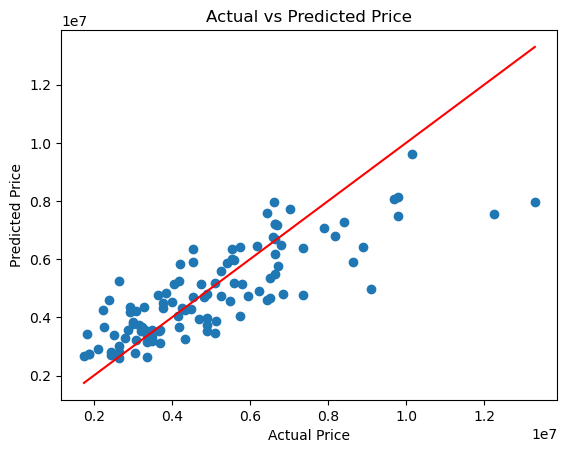

In [61]:
plt.scatter(y_test, y_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red'
)

plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted Price')
plt.show()

In [62]:
pred_df=pd.DataFrame({'Actual Value':y_test,'Predicted Value':y_pred,'Difference':y_test-y_pred})
pred_df

,Actual Value,Predicted Value,Difference
316,4060000,5.164654e+06,-1.104654e+06
77,6650000,7.224722e+06,-5.747223e+05
360,3710000,3.109863e+06,6.001368e+05
90,6440000,4.612075e+06,1.827925e+06
493,2800000,3.294646e+06,-4.946463e+05
...,...,...,...
15,9100000,4.973331e+06,4.126669e+06
357,3773000,4.336651e+06,-5.636509e+05
39,7910000,7.059063e+06,8.509373e+05
54,7350000,6.398941e+06,9.510591e+05


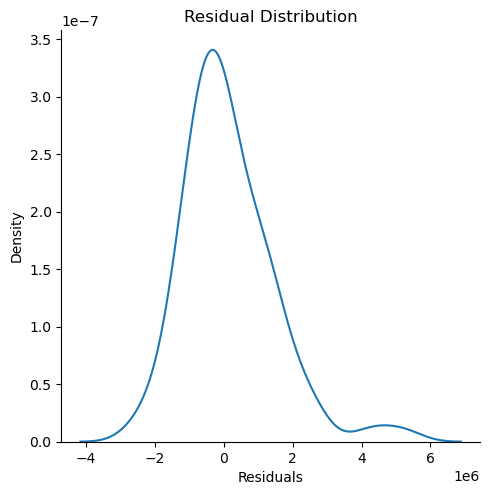

In [63]:
sns.displot(y_test-y_pred, kind='kde')
plt.xlabel('Residuals')
plt.title('Residual Distribution')
plt.show()